# **MMME4125 2026/2027 Coursework**

**Student Name:** Matthew Lewis

**Student ID:** 20611915

# **Project Description**

In this coursework, you will analise historical data and build your own machine learning pipeline demonstrating your knowledge on data exploration, data preparation and machine learning model development to solve a prediction or classification task  of an engineering domain problem.

**Dataset:** You will select a data set from a range of data sets provided in this module's Moodle page.

**Overall task:** Utilising your selected data set, you will build at least two models of your choice either for regression or classification (depending on the data set you selected) from the ones covered during lectures (e.g. NN, Decision Trees, Randon Forest, CNN to name a few examples). Employ appropriate methods from the pandas, matplotlib, keras and sklearn libraries to analyse and process the dataset and for building predictive models.

**Note:** You must use only pandas, numpy, matplotlib, keras and sklearn or any other specific library that was covered during class for example for data augmentation. Do not use other libraries or external packages. Use of such packages may receive zero credit for the affected parts. 

**Format:** Use this Jupyter Notebook as a template to write your report/answers to questions in Markdown cells, supported by your source code in Code cells.

The project (and this notebook) are structured in three main tasks:

**(Task 1)** -  Data set selection & data exploration : Once you select the data set you will carry out an initial Exploratory Data Analysis (EDA). Some data sets might be too large, containing multiple features or measurements of multiple variables. As you explore your data, you will make a decision of which sub set of your data you will use for your prediction/classification task. **You will then discuss this decision with your lab tutor (you will book a slot for this during lab hours) and get feedback**. As it will be indicated later in this notebook, you will add as markdown your analysis of the EDA results, the feedback provided by the tutor and how this has been taken into account to move to the next task. 

**(Task 2)** - Data preparation : with your chosen dataset (or subset), you will carry out the data preparation. This will include data visualisation (e.g. patterns, class imbalance, outliers), dealing with any missing values, outlier handling, scaling/normalisation, feature extraction, data reduction/augmentation, creating of training,validaton and test sets). 

**(Task 3)** - Model Development & Metrics Analysis : once your data set is ready, select two ML approaches from the ones covered during the lectures and discuss your selection with your lab tutor (**you will need to book a second lab slot for this and get feedback**). You will add in a Markdown cell your rationale for chosing such models, providing details of the feedback provided by the lab tutor and how it was used to move forward. Additional rationale for the specific hyper-parameters should also be included. Implementation should be added in a Code cell with appropriate code comments. Appropriate metrics for the model used should be implemented and presented (e.g. RMSE, Precision, Recall, F-Score, confusion matrix). You may want to try multiple hyper parameters to understand how the model behaves and if further iprovement can be obtained. In a Markdown cell, please explain the results obtained on both models and present a discussion of results. This discussion should include your insights on how model design/hyper-parameters affected the quality of the results.


Ensure your code produces the corresponding plots or results addressing the questions. Rename this .ipynb file to 202627_MMME4125_cw_XXX.ipynb, where XXX is your username (e.g., psxyz), and submit it to Moodle by **DATE**

**Marks**: The coursework is worth a total of 100 marks (accounting for 70% of the module grade). Marks will be awarded based on your understanding of machine learning theories, the informativeness and presentation of your code, visualisations, results (e.g., code comments, necessary labels in plots) and analysis, evidence of feedback and how it was addressed, your self-learning ability in solving the specific problem, and how succinct and clear your report writing is.

In [ ]:
# You can change the import statements as you wish, but you should not use any library beyond pandas, numpy, matplotlib, and sklearn.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
)

<div class="alert alert-success" style="text-align:left;">
<h2>Task 1. Dataset Selection & Exploratory Data Analysis<span style="float:right;">[25 marks]</span></h2></div>

### Task 1a. <span style="color:red">(10 marks)</span>

Start by introducing the engineering problem that you will be addressing, what the current industrial practice is to solve this problem and why ML is a good approach to solve it (3 marks). Explain the data set you have selected by providing details on what each variable represents, if you suspect there are any likely measurement problems, if there are any variables that could introduce leakage and if any mechanical principles may provide initial plausible relationships across these variables (5 marks).  Finally explain why this is a regression or a classification task (2 marks).

The problem that this machine learning model will be attempting to solve is that aircraft structures need a very large number of fastener holes to be drilled, usually done by robots. If any of these holes are faulty it leads to problems such as having to rework or scrap the structure. 
The current practice is that the holes are are inspected after they have been drilled and the drills are changed after they've done a fixed number of holes with some cells using only simple thrust or torque thresholds. These practices are slow and most importantly dont check all holes and only check after the damage is done.
Machine learning is a good approach as it is capable of checking as production is happening as oppose to after production. It is also capable of checking every single hole with almost no added time or cost. Machine learning can also use the servo motors that already exist on the drill and recorded at 1 kHz.

The selected dataset is the "Robotic drilling cycles" set. It contains 127 holes drilled into a single aluminium plate by an industrial robot. Each hole is recorded at 1kHz saved as its own file.
The variables recorded are:
- Index: a counter for the number of samples
- Time (ms): a time stamp for each sample, describes when the reading was taken
- INORM (A): The instantaneous servo motor current. The main indicator of cutting load as motor current is proportional to torque
- IEFF (A): The effective motor current. Measures the same load but has been smoothed
- POSF (mm): The position of the drill along its axis. shows the stage in the cycle.
- PSDATA:INORM (A): A second current chanel
- TCMD (%): The torque command sent to the motor

Potential measurement problems 
- IEFF is reading at -9A constantly whilst the machine is idle which could be a calibration issue
- INORM is recorded in whole numbers and jumps around a lot
- Anything at a higher frequency than 1kHz may not be captured

Potential leakage sources:
- Filenames contain the label itself
- Files have different lengths, the model may use this as a indicator without looking at the signal.
- Tool length, motor temperature and workpeice dimensions could correlate with anomaly labels

A key mechanical principle that provides a relationship is that motor current is roughly proportional to torque. The drilling torque depends on the material cutting force and feed per revolution. Therefore: 
- Current should rise only while POSF is advancing at feed rate 
- Current should drop at breakthrough
- Different material would change current e.g. plastic
- If there are 2 plates the cutting phase will be longer

This is a classification task as the goal is to find which category the hole belongs to not to find a number. Each whole is either normal or an anomoly so is a fixed category that needs to be defined.

### Task 1b. <span style="color:red">(5 marks)</span>

Select a subset of the data to be visualised. Include a rationale for inspecting this particular subset of data (2 mark). Produce at least 3 plots (1 mark each) to visualise patterns, distribution, class imbalance, outliers and correlations. The types of plots you use will  be determined by the type of data you are handling. These plots should be informative of the next steps you will carry out during data preparation.

Plotting every cycle would produce overlapping, unreadable figures, so a subset of 33 holes was selected for visualisation. From the 109 normal holes, 15 were chosen at random from both recording sessions. Random selection avoids bias towards holes drilled at a particular time or point in the tool's life, and a fixed random seed means the same holes are chosen every time the notebook runs. All 18 anomalous holes were kept, because each anomaly type has only one to seven examples and leaving any out could hide an anomaly type completely. Plot 3 focuses on the feed phase, when the drill is cutting, because that is where faults should appear.


In [12]:
#IMPORT LIBRARIES

import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt



# LOAD THE DRILLING CYCLES 
# The first two lines are a title and a blank line, the fourth line holds the units, so these are skipped.
# The class label is not stored inside the file: it comes from the filename prefix (no prefix = normal hole).

DATA_DIR = "/Users/matthewlewis/Downloads/Big"   # folder with the CSV files
SAMPLING_HZ = 1000                               # 1 reading every 1 ms
SIGNALS = ["INORM", "IEFF", "POSF"]              # current, effective current, position

PREFIX_TO_LABEL = {
    "_2Plates": "2Plates",
    "_Cardauto": "Card",
    "_Incomplete": "Incomplete",
    "_1 0mm": "1.0mm",
    "_Plastic": "Plastic",
    "_WrongSpeeds": "WrongSpeeds",
}

def get_label(filename):
    for prefix, label in PREFIX_TO_LABEL.items():
        if filename.startswith(prefix):
            return label
    return "Normal"

rows = []
for path in sorted(glob.glob(os.path.join(DATA_DIR, "*.csv"))):
    filename = os.path.basename(path)
    cycle = pd.read_csv(path, skiprows=[0, 1, 3])
    rows.append({
        "File": filename,
        "Label": get_label(filename),
        # Recording session, from the filename. Used ONLY to make sure both
        # drilling programs appear in every split - never as a model input.
        "Session": "Feb2024" if "Feb" in filename else "Sep2024",
        "N_samples": len(cycle),
        # Store each signal as an array, like the Vibration_X/Y/Z columns in the skeleton
        **{s: cycle[s].to_numpy(dtype=float) for s in SIGNALS},
    })

df = pd.DataFrame(rows)
print("Number of cycles:", len(df))
print(df["Label"].value_counts())

Number of cycles: 127
Label
Normal         109
2Plates          7
Card             4
1.0mm            2
Incomplete       2
Plastic          2
WrongSpeeds      1
Name: count, dtype: int64


In [13]:
# SELECT THE SUBSET TO VISUALISE
# A random sample of 15 normal holes is taken from both sessions,
# and ALL anomalous holes are kept because each anomaly type has only
# 1-7 examples. A fixed random_state makes the sample repeatable.

N_NORMAL = 15

normal_sample = df[df["Label"] == "Normal"].sample(n=N_NORMAL, random_state=42)
anomalies = df[df["Label"] != "Normal"]

subset = pd.concat([normal_sample, anomalies]).reset_index(drop=True)
CLASSES = ["Normal", "2Plates", "1.0mm", "Card", "Incomplete", "Plastic", "WrongSpeeds"]

print("Cycles in subset:", len(subset))
print(subset["Label"].value_counts().reindex(CLASSES))

Cycles in subset: 33
Label
Normal         15
2Plates         7
1.0mm           2
Card            4
Incomplete      2
Plastic         2
WrongSpeeds     1
Name: count, dtype: int64


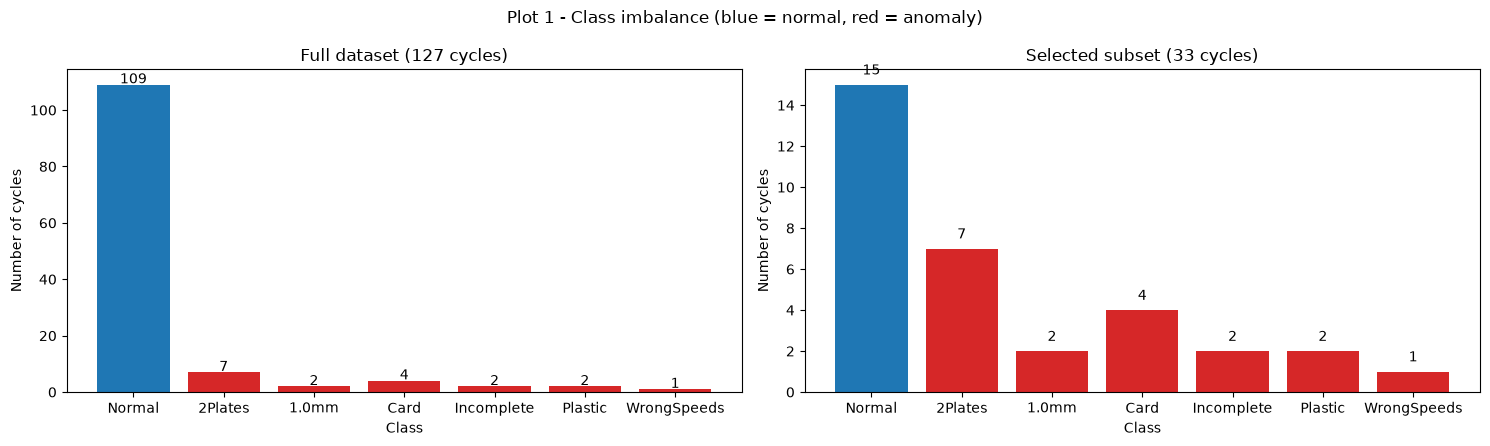

In [14]:
# PLOT 1. CLASS IMBALANCE
# Left: number of cycles per class in the full dataset.
# Right: number of cycles per class in the selected subset.
# This shows how rare each anomaly is compared with normal holes.

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))

for ax, data, title in [(axes[0], df, f"Full dataset ({len(df)} cycles)"),
                        (axes[1], subset, f"Selected subset ({len(subset)} cycles)")]:
    counts = data["Label"].value_counts().reindex(CLASSES, fill_value=0)
    colours = ["tab:blue" if c == "Normal" else "tab:red" for c in CLASSES]
    ax.bar(CLASSES, counts, color=colours)
    for i, n in enumerate(counts):
        ax.text(i, n + 0.5, int(n), ha="center")
    ax.set_title(title)
    ax.set_xlabel("Class")
    ax.set_ylabel("Number of cycles")

fig.suptitle("Plot 1 - Class imbalance (blue = normal, red = anomaly)")
plt.tight_layout()
plt.show()

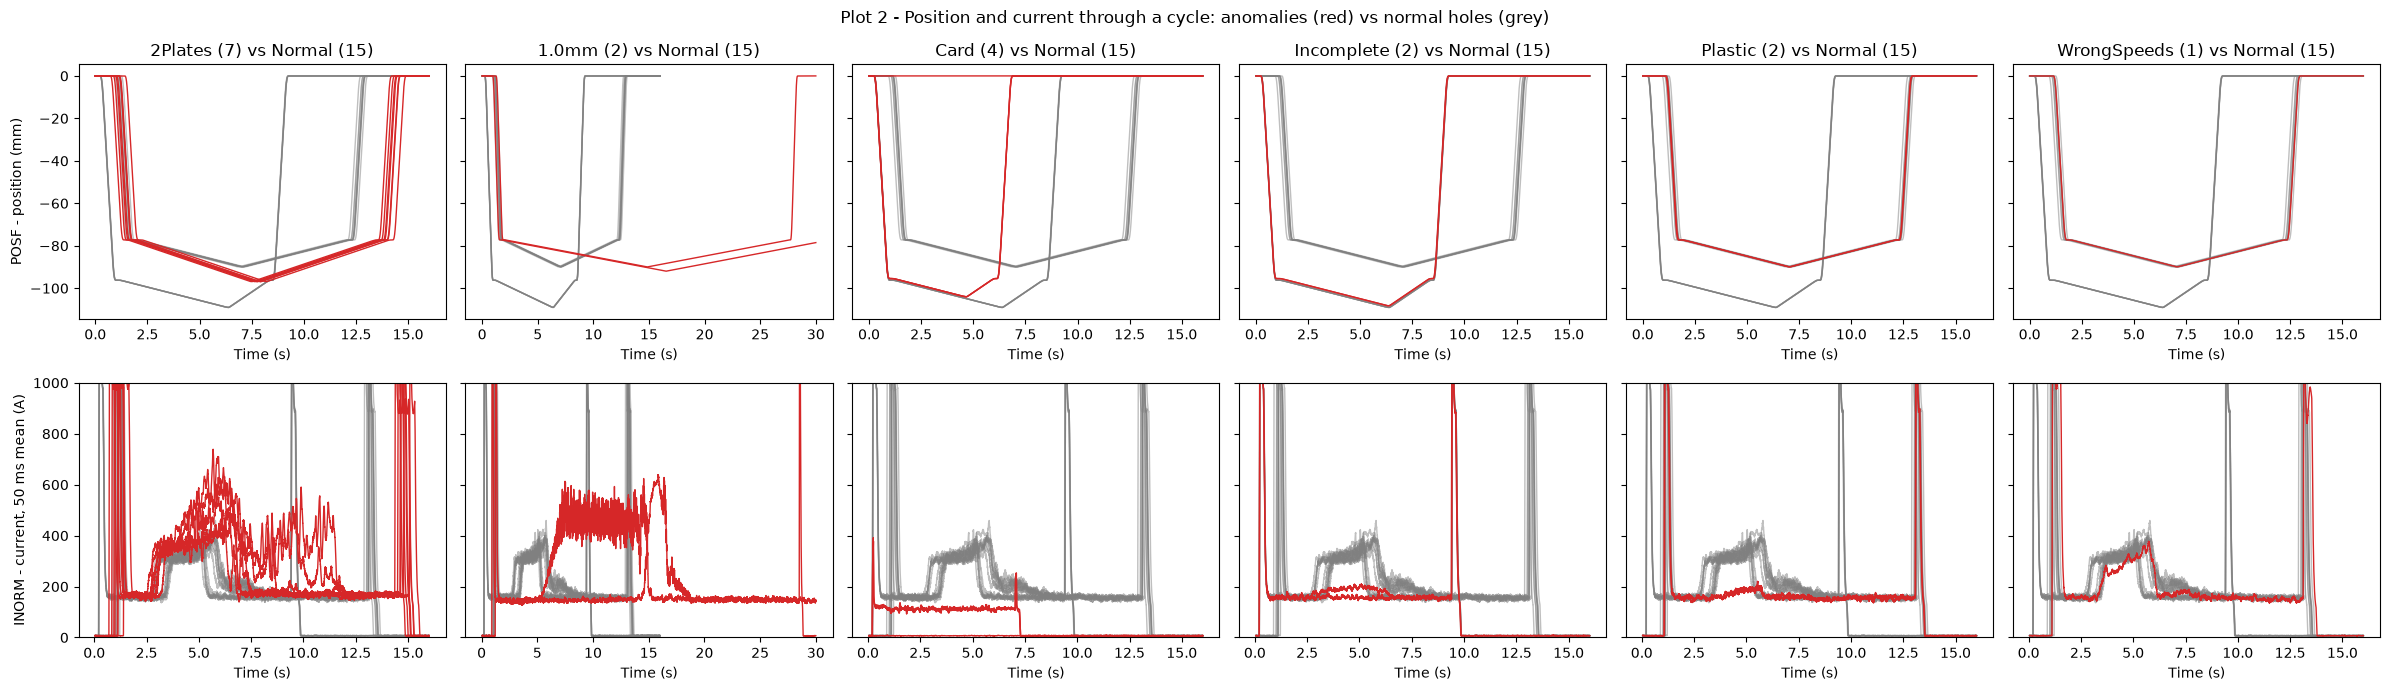

In [15]:
# PLOT 2. THE SIGNALS THROUGH ONE CYCLE, BY CLASS
# Top row: drill position (POSF). Bottom row: motor current (INORM),
# smoothed with a 50 ms moving average so the cutting load is readable.
# Each anomaly type (red) is drawn over the sampled normal holes (grey).

def smooth(signal, n=50):
    return pd.Series(signal).rolling(n).mean().to_numpy()

fig, axes = plt.subplots(2, len(CLASSES) - 1, figsize=(24, 7), sharey="row")
normals = subset[subset["Label"] == "Normal"]

for col, label in enumerate(CLASSES[1:]):
    holes = subset[subset["Label"] == label]
    for row, signal in enumerate(["POSF", "INORM"]):
        ax = axes[row, col]
        for group, colour, alpha in [(normals, "grey", 0.5), (holes, "tab:red", 1.0)]:
            for _, hole in group.iterrows():
                y = smooth(hole[signal]) if signal == "INORM" else hole[signal]
                t = np.arange(len(y)) / SAMPLING_HZ
                ax.plot(t, y, color=colour, alpha=alpha, lw=1)
        if row == 0:
            ax.set_title(f"{label} ({len(holes)}) vs Normal ({len(normals)})")
        ax.set_xlabel("Time (s)")

axes[0, 0].set_ylabel("POSF - position (mm)")
axes[1, 0].set_ylabel("INORM - current, 50 ms mean (A)")
axes[1, 0].set_ylim(0, 1000)   # hide the ~2400 A spikes from fast moves so cutting is visible
fig.suptitle("Plot 2 - Position and current through a cycle: anomalies (red) vs normal holes (grey)")
plt.tight_layout()
plt.show()

No feed phase found in _Cardauto$003 (1).csv - check this recording


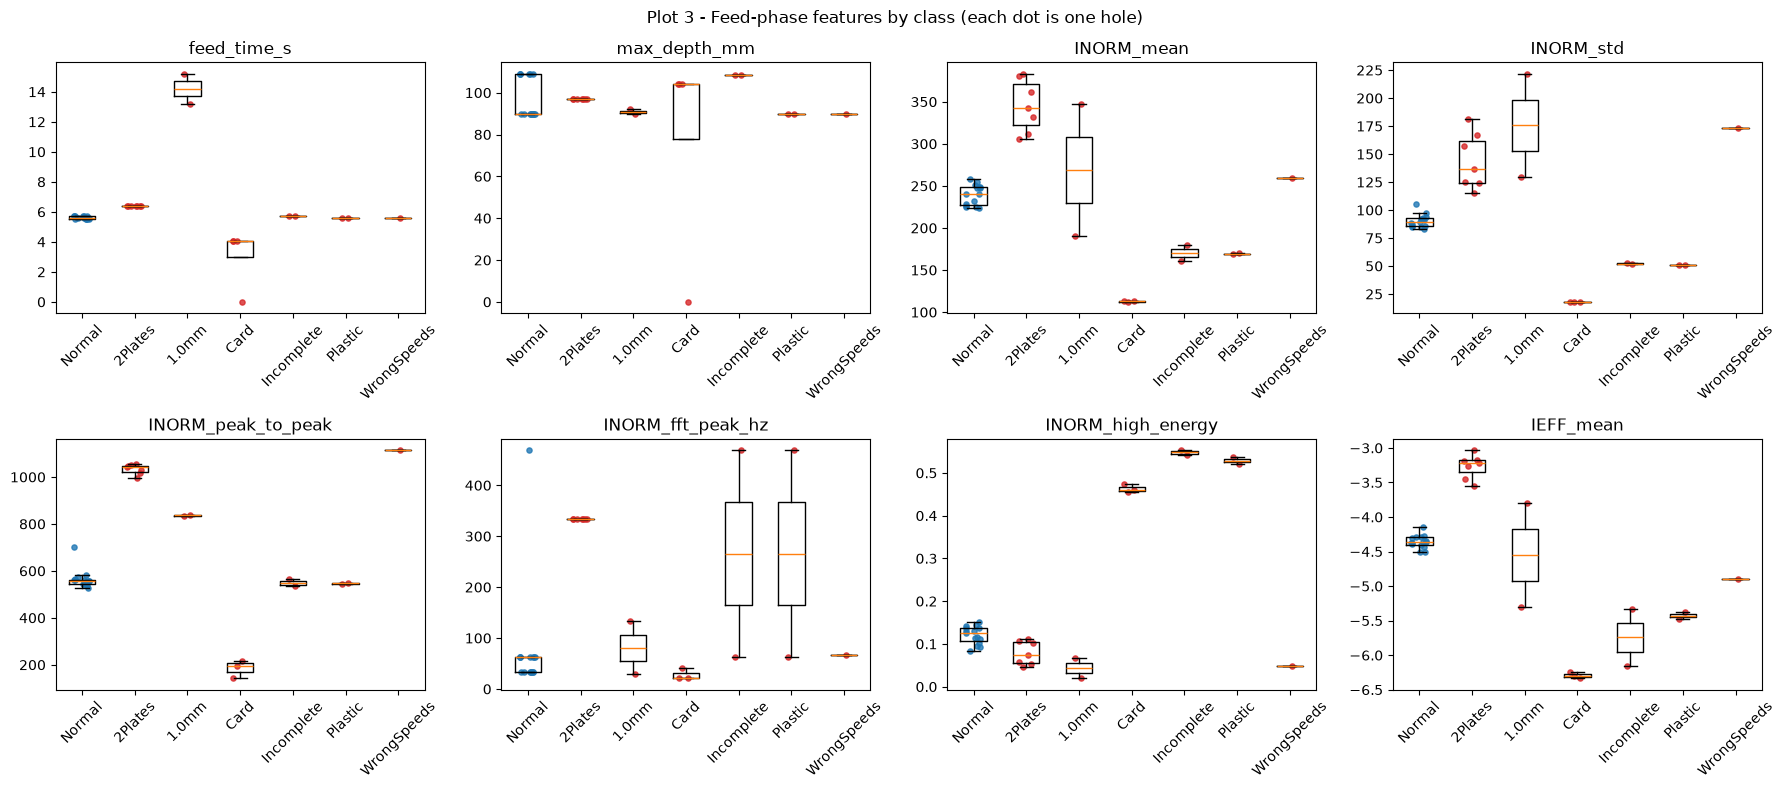

             feed_time_s  max_depth_mm  INORM_mean  INORM_std  \
Label                                                           
Normal              5.63         97.57      239.84      90.28   
2Plates             6.39         96.88      345.28     143.77   
1.0mm              14.20         90.97      268.70     175.75   
Card                3.02         78.03      112.57      18.15   
Incomplete          5.74        108.26      169.95      52.25   
Plastic             5.56         89.91      169.24      50.76   
WrongSpeeds         5.56         89.91      259.17     173.09   

             INORM_peak_to_peak  INORM_fft_peak_hz  INORM_high_energy  \
Label                                                                   
Normal                   565.20              75.92               0.12   
2Plates                 1033.43             333.55               0.08   
1.0mm                    836.00              81.15               0.04   
Card                     184.33              27.7

In [16]:
# PLOT 3. FEATURE DISTRIBUTIONS AND OUTLIERS
# As in the skeleton (step 6A), each cycle is summarised by simple
# statistical and FFT features. Here they are calculated on INORM
# during the FEED phase only, when the drill is cutting.
# The feed phase is found from the drill speed: slow downward movement
# (0.2-10 mm/s); the fast moves before and after run at ~167 mm/s.

def feed_phase(hole, trim=200):
    speed = pd.Series(hole["POSF"]).diff(50) / 0.05      # mm/s over 50 ms
    is_feed = ((speed < -0.2) & (speed > -10)).to_numpy()
    # Drop the first and last 200 ms of the feed so the current spikes from
    # the fast moves either side are not counted as cutting
    idx = np.where(is_feed)[0]
    feed = np.zeros(len(is_feed), dtype=bool)
    if len(idx) > 2 * trim:              # a cycle with no feed (drill never moved) stays all False
        feed[idx[0] + trim: idx[-1] - trim] = True
    return feed

def make_features(rows):
    result = []
    for _, hole in rows.iterrows():
        feed = feed_phase(hole)
        if feed.sum() == 0:              # no cutting found: record the hole but leave its features empty
            print("No feed phase found in", hole["File"], "- check this recording")
            result.append({"feed_time_s": 0, "max_depth_mm": -hole["POSF"].min()})
            continue
        signal = hole["INORM"][feed]
        spectrum = np.abs(np.fft.rfft(signal - signal.mean()))
        frequencies = np.fft.rfftfreq(len(signal), d=1 / SAMPLING_HZ)
        power = spectrum ** 2
        result.append({
            "feed_time_s": feed.sum() / SAMPLING_HZ,
            "max_depth_mm": -hole["POSF"].min(),
            "INORM_mean": signal.mean(),
            "INORM_std": signal.std(),
            "INORM_rms": np.sqrt(np.mean(signal ** 2)),
            "INORM_peak_to_peak": np.ptp(signal),
            # strongest frequency above 5 Hz (below that is the slow change in load)
            "INORM_fft_peak_hz": frequencies[frequencies > 5][np.argmax(spectrum[frequencies > 5])],
            "INORM_high_energy": power[frequencies >= 100].sum() / (power.sum() + 1e-12),
            "IEFF_mean": hole["IEFF"][feed].mean(),
        })
    return pd.DataFrame(result, index=rows.index)

features = make_features(subset)
features["Label"] = subset["Label"]

to_plot = ["feed_time_s", "max_depth_mm", "INORM_mean", "INORM_std",
           "INORM_peak_to_peak", "INORM_fft_peak_hz", "INORM_high_energy", "IEFF_mean"]
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, feature in zip(axes.flat, to_plot):
    data = [features.loc[features["Label"] == c, feature].dropna() for c in CLASSES]
    ax.boxplot(data, showfliers=False)
    for i, (c, values) in enumerate(zip(CLASSES, data), start=1):
        jitter = np.random.default_rng(0).uniform(-0.15, 0.15, len(values))
        ax.scatter(i + jitter, values, s=14, alpha=0.8,
                   color="tab:blue" if c == "Normal" else "tab:red")
    ax.set_xticks(range(1, len(CLASSES) + 1))
    ax.set_xticklabels(CLASSES, rotation=45)
    ax.set_title(feature)
fig.suptitle("Plot 3 - Feed-phase features by class (each dot is one hole)")
plt.tight_layout()
plt.show()

print(features.groupby("Label")[to_plot].mean().reindex(CLASSES).round(2))

### Task 1c. <span style="color:red">(10 marks)</span>

-By using your plots from 1b, provide an analysis of the data (e.g. observed patterns, correlations, potential best predictors) and briefly explain how each code snippet supports your evaluation of potential issues with the data (5 marks).

-Once you have done your analysis/insights you should discuss this with your lab tutor (you need to book a slot in lab hours for this), capture that feedback, report it here as well as a reflection of how the feedback informs the next steps of data processing (5 marks).


Class imbalance (Plot 1): The data set is imbalanced as there are 109 normal holes against 18 anomalies, and some of the anomalies have very few examples, such as WrongSpeeds only having one and 1.0mm, Incomplete and Plastic only having 2 each. This creates a problem in that if a model labelled every hole as normal it would have an 86% accuracy, so the model can't be judged by accuracy alone. As a result, other metrics such as recall, F1 score and a confusion matrix must be used instead. Because some of the anomaly types only have one or two examples there are too few to both train and test a classifier on each type of anomaly. The task will therefore be treated as normal hole vs anomaly detection where the model will be trained on normal holes and flag anything that doesn't look normal. The normal holes will be split into the training and test sets, and all anomalies will be placed in the test set so that every anomaly type can be checked and the normal holes checked for false alarms.

Patterns in the raw signals (Plot 2): Every cycle follows the same pattern of a fast approach to the surface, a slow feed where the drill cuts, a slow retract back out of the hole and a fast return away from the surface. The normal holes follow two slightly different paths, because the two recording sessions used different drilling programs. The motor current is low and steady except during cutting and the very large spikes during the fast movements to and from the surface. These spikes do not come from the cutting but instead the acceleration of the drill to and from the surface, therefore the analysis for the holes must focus on the feed phase or they will dominate features calculated over the whole cycle. 2Plates and 1.0mm change the drill's path (deeper and slower respectively), but Plastic and WrongSpeeds follow the same path as normal so can't be told apart this way. The graphs show how each anomaly changes the current in cutting:
- 2Plates - Starts cutting earlier and draws more current for longer with irregular peaks.
- 1.0mm - Has a much longer cutting period. The two holes behave very differently with one staying near the low "in air" level for most of the feed.
- Plastic - Peaks at the same time as normal but the peak is very small in comparison
- WrongSpeeds - Very similar shape to a normal hole but rises slightly more gradually.
- Card - The current stays flat at around 120A, below even the "in air" level, with no peak.
- Incomplete - Stops short of the normal depth, and the current only rises slightly.
One Card recording shows the drill never moving and the current near zero. This is a failed recording rather than a real hole.

Feature distributions and best predictors (Plot 3): Normal holes form reasonably tight groups on every feature so can be easily compared to anomaly types which all show a difference at least once. The best potential predictors for each anomaly are:
- 2PLates - INORM mean, INORM standard deviation and INORM peak to peak.
- Plastic - INORM mean and INORM high frequency energy ratio
- 1.0mm - Feed time, INORM standard deviation and INORM peak to peak.
- WrongSpeeds - INORM standard deviation and INORM peak to peak.
- Card - INORM mean, INORM standard deviation, feed time  and INORM high-frequency energy ratio.
- Incomplete - INORM mean and INORM high-frequency energy ratio.

Code Snippets:
- Loading Data cell: Labels exist in the filenames, which is a leakage risk if used as inputs. No missing values or duplicate files were found.
- Subset cell: Confirmed the class counts and how few anomolies there are
- Plot 1: Visually showed and quantified the imbalance, helping with the choice of split and metrics as described above.
- Plot 2: Showed the acceleration spikes, the noise in INORM and the different cycle lengths, which all need to be considered during the data preperation. It also showed how the two drilling programs are different and that one of the card recordings failed.
- Plot 3: Showed which features were useful in identifying each class and which aren't necessary.


<div class="alert alert-success" style="text-align:left;">
<h2>Task 2. Data Preparation<span style="float:right;">[40 marks]</span></h2></div>

### <span style="color:red">IMPORTANT NOTE: </span> 
This the beginning of your ML building pipeline. All transformations that happen to the data from here onwards may be stateless or stateful. Make a concious decision at which step of the entire process you need to split your data set into training, validation and test set. **Add an additional Code cell** for data splitting when you think it is reasonable to do so as well as **add a Markdown cell** to explain why the data set is splitted at this point of the ML pipeline and the impact data transformation operations might have on the validity of the model if the splitting is not carried out beforehand. You should also justify your train-validation-test splitting stategy.
### <span style="color:red">(8 marks) </span>

### Task 2a. Data Cleaning <span style="color:red">(7 marks)</span>
Using the libraries specificied at the top of the notebook or any other one covered in class, start cleaning your data by handling missing values, handling any duplicates and deal with outliers. Justify your methods.

*Task 2a. Add your justification here*

In [ ]:
# Task 2a. Add your code here

### Task 2b. Data Transformation <span style="color:red">(5 marks)</span>
Perform any necessary normalisation and encoding of categorical variables. Please explain why this step is necessary when building a predictive model and justify the method used.

In [ ]:
# Task 2b. Add your code here

*Task 2b. Add your explanation here*

### Task 2c. Data Reduction/Augmentation  <span style="color:red">(10 marks)</span>

Based on your data set implement either data reduction or data augmentation depending on the needs of the problem and data (5 marks). Explain why data reduction or data augmentation is necessary in the context of your engineering problem and the data set you selected as well as justify the methods used (5 marks). One thing to note is that depending on your data set, data reduction might have to be done after Task 2d Feature Engineering, so make sure you apply these two steps (Task 2c and Task 2d) in the correct order according to your data. 

**Note**: If you do have to do 2d before 2c, then just make sure your code is in the correct order in the code cells below.

In [ ]:
# Task 2c. Add your code here

*Task 2c. Add your explanation and justification here*

### Task 2d. Feature Engineering   <span style="color:red">(10 marks)</span>

An important aspect of machine learning is understanding the feature space and shaping it before training. That is, preprocessing or reshaping the data in a way that provides more relevant information and an easier job for the regressor or classifier.

Perform any feature engineering that you might think it is ideal for the type of task you are aiming (4 marks). This could include statistical features, rolling window statistics,  frequency analysis (FFT) or any others covered in lectures. 

If either you are going to work directly with the raw data, or you will be engineering features, justify why this is the case in the context of the engineering problem you are trying to solve, justifying any specific features used (3 marks). In the case of raw data, perform any additional transformation that would be needed to work with this raw data directly. 

Assess whether all data is ready for model building. If not, complete the preparation of a model-ready dataframe from your cleaned dataset. More specifically, make sure to assess whether all predictors in your prepared dataframe are directly suitable for the machine learning task, state why this is the case  and state what(if anything) still needs processing, and process / make the necessary adjustment in the data accordingly (3 marks).

In [ ]:
# Task 2c. Add your code here

Task 2c. Add your explanations/justifications here

<div class="alert alert-success" style="text-align:left;">
<h2>Task 3. ML Model Building<span style="float:right;">[35 marks]</span></h2></div>

### Task 3a. Building a base  model <span style="color:red">(10 marks)</span>

Now, after meeting your tutor for the second time to discuss your preliminary model selection and reasons for such method (you need to book again a slot during your lab for this) select and build a baseline model from scratch (e.g. define architecture in the case of NN) to predict or classify according to your problem using the preprocessed dataset. 

- Train the model and report **three different** evaluation metrics (3 marks).
- Reflecting from  your tutor feedback, explain how this feedback influenced the ML model selected, why is it appropriate for the task? why the hyper-parameters used? (4 marks)
- For each metric, explain (in a single short sentence) why it is relevant and whether the observed value suggests sensible predictions/classifications, i.e. what the values within the metric mean (3 marks). 

In [ ]:
#Add your code here

Add your justification for metrics here and what the results obtained mean.

### Task 3b. Hyper-parameter exploration <span style="color:red">(10 marks)</span>

You have now build a base model, with some initial results. It is now your task to experiment with hyper-parameters (5 marks) to see if you can improve the quality of your results. It is up to you how you approach this process, but you need to justify (5 marks ) the approach you are taking and discuss the results. What effect is having the changes you are doing to the approach?

In [ ]:
#perform your different hyper-parameter optimisation/changes here

Add here your justification for how you are approaching the hyper-parameter tuning  and discuss your results.

### Task 3c. Additional Models and Final Analysis <span style="color:red">(15 marks)</span>

Implement at least one more method of your choice.Report model quality with clear evidence (metrics). Compare with the baseline using supportive tables or visualisations (4 marks), and discuss the strengths and limitations of each (3 marks). Finally, provide a discussion (8 marks) on:

Why this type of model and would you deploy it in a real environment? why?

Under what operating conditions would you not trust it? how could you improve it?

What additional sensor would you collect and why?

Are the important features physically plausible?

In [ ]:
# your implementaiton of additional methods here together with metrics

Add here your discussion on strengths and limitations of each method